In [1]:
#Here each molecule is considered as a node. So here there is only one graph.

In [2]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import AllChem
from rdkit import DataStructs
from rdkit.Chem import Descriptors
from rdkit.Chem import rdMolDescriptors
import networkx as nx

In [3]:
import matplotlib.pyplot as plt

In [4]:
df1 = pd.read_csv('./ido1_tdo_common_1126.csv', na_values=['na'])
df1 = df1.dropna(ignore_index=True)
df1

,molecule_chembl_id,smiles,ido1_ic50,tdo_ic50
0,CHEMBL1909734,Clc1ccccc1-c1cnn[nH]1,86000.0,100000.0
1,CHEMBL2147992,CCc1cccc(-c2c[nH]nn2)c1,13000.0,100000.0
2,CHEMBL2148074,Oc1ccc(Cl)cc1-c1c[nH]nn1,330.0,100000.0
3,CHEMBL4287290,N#Cc1nccc2c(Nc3ccc(F)c(Cl)c3)c(N)oc12,200.0,500.0
4,CHEMBL4282281,Nc1oc2c(-c3ccncc3)nc(F)cc2c1Nc1ccc(F)c(Cl)c1,200.0,500.0
...,...,...,...,...
1121,CHEMBL5974732,Cc1sc2cncn2c1C(O)CC1CCCC1,190.0,573.0
1122,CHEMBL5750760,CC[C@H](C)c1sc2cncn2c1C(O)C1CCCCC1,172.0,962.0
1123,CHEMBL5427485,CN1CCN(CCc2ccc3nc4n(c(=O)c3c2)C2C=CC(F)=CC2C4=...,20.0,90.0
1124,CHEMBL5798663,O=C(CC1c2ccccc2-n2cncc21)C1CCCCC1,550.0,100.0


In [5]:
df2 = df1.loc[:, ['ido1_ic50', 'tdo_ic50']]
df2

,ido1_ic50,tdo_ic50
0,86000.0,100000.0
1,13000.0,100000.0
2,330.0,100000.0
3,200.0,500.0
4,200.0,500.0
...,...,...
1121,190.0,573.0
1122,172.0,962.0
1123,20.0,90.0
1124,550.0,100.0


In [6]:
for i in range(len(df2)):
    if df2['ido1_ic50'].values[i] <= 1000:
        df2.loc[i, ['ido1_ic50']] = 1
    else: 
        df2.loc[i, ['ido1_ic50']] = 0

In [7]:
for i in range(len(df2)):
    if df2['tdo_ic50'].values[i] <= 1000:
        df2.loc[i, ['tdo_ic50']] = 1
    else: 
        df2.loc[i, ['tdo_ic50']] = 0

In [8]:
newcol = []
for i in range(len(df2)):
    if df2['ido1_ic50'].values[i] == 1.0 and df2['tdo_ic50'].values[i] == 1.0:
        newcol.append('AA')
    elif df2['ido1_ic50'].values[i] == 0.0 and df2['tdo_ic50'].values[i] == 0.0:
        newcol.append('II')
    elif df2['ido1_ic50'].values[i] == 0.0 and df2['tdo_ic50'].values[i] == 1.0:
        newcol.append('IA')
    else:
        newcol.append('AI')

In [9]:
target = pd.DataFrame(data=newcol, columns=['ido_tdo'])
target

,ido_tdo
0,II
1,II
2,AI
3,AA
4,AA
...,...
1121,AA
1122,AA
1123,AA
1124,AA


In [10]:
y = target.values.reshape(len(df2),)
y.shape

(1126,)

In [11]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [12]:
y_label = encoder.fit_transform(y)

In [13]:
y_label

array([3, 3, 1, ..., 0, 0, 3])

In [14]:
from rdkit.Chem import SaltRemover as sr
remover = sr.SaltRemover()

In [15]:
mols = []
for i in range(len(df1)):
    try:
        mol_i = Chem.MolFromSmiles(df1['smiles'][i])
        if mol_i is None:
            print(f"[WARNING] Invalid SMILES at index {i}, skipping.")
            mols.append(None)  # Maintain indexing for multiprocessing
            continue
        mol_i = remover.StripMol(mol_i, dontRemoveEverything=True)
        mols.append(mol_i)
    except Exception as e:
        print(e)
len(mols)

1126

In [16]:
smiles_list = [df1['smiles'][i] for i in range(len(df1['smiles']))]

In [17]:
names_list = [df1['molecule_chembl_id'][i] for i in range(len(df1['molecule_chembl_id']))]

In [ ]:
#Deprecated method!
FPs = [AllChem.GetMorganFingerprintAsBitVect(mols[i], radius=3, nBits=1024) for i in range(len(mols))]

In [19]:
similarity_matrix = np.zeros((len(FPs), len(FPs)))

In [20]:
similarity_matrix.shape

(1126, 1126)

In [21]:
#only works for bit vectors or sparse count vectors, not arbitrary numerical vectors.
DataStructs.TanimotoSimilarity(FPs[10], FPs[10])

1.0

In [22]:
#Calculate the diagonal elements
for i in range(len(FPs)):
    for j in range(i, len(FPs)):  # Avoid duplicate calculations
        similarity = DataStructs.TanimotoSimilarity(FPs[i], FPs[j])
        similarity_matrix[i, j] = similarity
        similarity_matrix[j, i] = similarity

In [23]:
similarity_matrix.shape

(1126, 1126)

In [24]:
import seaborn as sns

In [25]:
similarity_matrix.min(), similarity_matrix.max(), similarity_matrix.mean()

(0.017241379310344827, 1.0, 0.12398849920188615)

In [26]:
#Step 1: Compute Morgan fingerprints

In [27]:
# Suppose you have a list of SMILES strings for your molecules
def morgan_fp(smiles, radius=2, nBits=1024):
    mol = Chem.MolFromSmiles(smiles)
    fpgen = AllChem.GetMorganGenerator(fpSize=1024)
    arr_fp = fpgen.GetFingerprintAsNumPy(mol)
    return arr_fp

node_features = np.array([morgan_fp(s) for s in smiles_list])  # shape (1126, 1024)
y_label = np.array(y_label)
num_nodes = node_features.shape[0]

In [28]:
node_features.shape

(1126, 1024)

In [29]:
import numpy as np
import torch
import networkx as nx
from rdkit import Chem
from rdkit.Chem import AllChem
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity
from torch_geometric.data import Data
from torch_geometric.utils import subgraph

In [30]:
import random
import numpy as np
import torch

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [31]:
y_label

array([3, 3, 1, ..., 0, 0, 3])

In [32]:
y

array(['II', 'II', 'AI', ..., 'AA', 'AA', 'II'], dtype=object)

In [33]:
df1.index.to_numpy()

array([   0,    1,    2, ..., 1123, 1124, 1125])

In [34]:
# Scaffold split (Bemis-Murcko), replacing random/stratified split to prevent
# structural leakage between train/val/test.
#
# Method: molecules are grouped by their Bemis-Murcko scaffold (Bemis & Murcko,
# J. Med. Chem. 1996); each scaffold group is then assigned WHOLE to a single
# split, so no two structurally near-identical molecules (sharing a scaffold)
# can appear on both sides of a train/test boundary. Scaffold groups are sorted
# largest-first and greedily filled into train, then val, then test until each
# target size is reached -- the standard convention used by MoleculeNet/DeepChem's
# ScaffoldSplitter.
#
# NOTE: unlike stratified random splitting, this does NOT guarantee proportional
# class representation in each split -- an entire rare class's molecules can
# share one scaffold and be assigned together to a single split. Given the small
# size of class IA (n=10) in this dataset, the diagnostics below explicitly check
# for this and must be reviewed before proceeding.

import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from collections import defaultdict


def generate_scaffold(smiles, include_chirality=False):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=include_chirality)


def scaffold_split_indices(indices, smiles_list, y_label, train_ratio=0.6, val_ratio=0.2, seed=42):
    """
    Bemis-Murcko scaffold split. indices, smiles_list, and y_label must be
    positionally aligned (same order), matching the convention of the original
    stratified_split_indices function.

    Returns train_idx, val_idx, test_idx as arrays of the original index values.
    """
    indices = np.asarray(indices)
    smiles_arr = np.asarray(smiles_list)
    y_arr = np.asarray(y_label)
    assert len(indices) == len(smiles_arr) == len(y_arr), "indices, smiles_list, y_label must be the same length and aligned"

    scaffold_to_indices = defaultdict(list)
    n_invalid = 0
    for idx, smi in zip(indices, smiles_arr):
        scaffold = generate_scaffold(smi)
        if scaffold is None:
            n_invalid += 1
            scaffold = f"__invalid_{idx}__"   # unparseable SMILES: isolate as its own group
        elif scaffold == "":
            scaffold = f"__acyclic_{idx}__"    # fully acyclic molecule: no ring scaffold, isolate as its own group
        scaffold_to_indices[scaffold].append(idx)
    if n_invalid:
        print(f"WARNING: {n_invalid} molecule(s) had unparseable SMILES; each was isolated as its own scaffold group.")

    # Shuffle (for reproducibility/tie-breaking) then sort scaffold groups largest-first
    rng = np.random.default_rng(seed)
    scaffold_groups = list(scaffold_to_indices.values())
    order = rng.permutation(len(scaffold_groups))
    scaffold_groups = [scaffold_groups[i] for i in order]
    scaffold_groups.sort(key=len, reverse=True)

    n_total = len(indices)
    n_train_target = int(np.floor(train_ratio * n_total))
    n_val_target = int(np.floor(val_ratio * n_total))

    train_idx, val_idx, test_idx = [], [], []
    for group in scaffold_groups:
        if len(train_idx) + len(group) <= n_train_target:
            train_idx.extend(group)
        elif len(val_idx) + len(group) <= n_val_target:
            val_idx.extend(group)
        else:
            test_idx.extend(group)

    return np.array(train_idx), np.array(val_idx), np.array(test_idx)


train_idx, val_idx, test_idx = scaffold_split_indices(
    df1.index.to_numpy(),
    df1['smiles'].to_numpy(),
    y_label,
    train_ratio=0.6,
    val_ratio=0.2,
    seed=42
)

print("Train size:", len(train_idx))
print("Val size:", len(val_idx))
print("Test size:", len(test_idx))

# --- Diagnostics: class distribution per split, and explicit leakage/coverage checks ---
y_series = pd.Series(np.asarray(y_label), index=df1.index.to_numpy())
class_names = {0: "AA", 1: "AI", 2: "IA", 3: "II"}  # adjust if your label encoding differs

print("\nClass distribution per split:")
dist_table = pd.DataFrame({
    "Train": y_series.loc[train_idx].value_counts(),
    "Val":   y_series.loc[val_idx].value_counts(),
    "Test":  y_series.loc[test_idx].value_counts(),
}).fillna(0).astype(int).sort_index()
dist_table.index = dist_table.index.map(lambda c: class_names.get(c, c))
print(dist_table)

# Correctness checks: no leakage, full coverage
all_idx = set(train_idx) | set(val_idx) | set(test_idx)
assert all_idx == set(df1.index.to_numpy()), "Index coverage mismatch after scaffold split!"
assert len(set(train_idx) & set(val_idx)) == 0, "Leakage detected: train/val overlap!"
assert len(set(train_idx) & set(test_idx)) == 0, "Leakage detected: train/test overlap!"
assert len(set(val_idx) & set(test_idx)) == 0, "Leakage detected: val/test overlap!"
print("\nNo scaffold leakage between splits; full coverage confirmed.")

# Explicit warning for any class missing (0 examples) from a split -- this WILL
# happen with small classes under scaffold splitting and needs your attention,
# not silent failure downstream (e.g. in classification_report or training).
for split_name, idx in [("Train", train_idx), ("Val", val_idx), ("Test", test_idx)]:
    present_classes = set(y_series.loc[idx].unique())
    missing = set(class_names) - present_classes
    if missing:
        missing_names = [class_names[c] for c in missing]
        print(f"\n*** WARNING: {split_name} split has ZERO examples of class(es): {missing_names} ***")
        print("    This is a known risk of scaffold splitting with small classes (e.g. IA, n=10).")
        print("    Review before proceeding -- consider a different seed, a coarser scaffold")
        print("    (e.g. generic/skeleton scaffold), or explicitly discussing this limitation.")

Train size: 675
Val size: 225
Test size: 226

Class distribution per split:
    Train  Val  Test
AA    285   87    58
AI    193   61    82
IA     27   14    11
II    170   63    75

No scaffold leakage between splits; full coverage confirmed.


In [35]:
svd = TruncatedSVD(n_components=256, random_state=42)
X = svd.fit_transform(node_features)

In [36]:
X.shape

(1126, 256)

In [37]:
#Mutual k-NN graph (with normalized squared weights)
k = 15
max_w = np.max(similarity_matrix ** 2)

edges = set()
for i in range(num_nodes):
    sims = similarity_matrix[i]
    nn_idx = np.argsort(sims)[::-1][1:k+1]
    for j in nn_idx:
        edges.add((i, j))

G = nx.Graph()
#G.add_nodes_from(range(num_nodes))  # keep isolated nodes

for i, j in edges:
    if (j, i) in edges:
        w = (similarity_matrix[i, j] ** 2) / max_w
        G.add_edge(i, j, weight=w)


In [38]:
G.number_of_nodes(), G.number_of_edges()

(1110, 5360)

In [39]:
#Convert to PyG Data object
edge_index = []
edge_attr = []

for u, v, data in G.edges(data=True):
    edge_index.append([u, v])
    edge_index.append([v, u])
    edge_attr.append([data["weight"]])
    edge_attr.append([data["weight"]])

edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()
edge_attr = torch.tensor(edge_attr, dtype=torch.float)

x = torch.tensor(X, dtype=torch.float)
y = torch.tensor(y_label, dtype=torch.long)

data = Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y)
data.num_classes = len(np.unique(y_label))


In [40]:
data

Data(x=[1126, 256], edge_index=[2, 10720], edge_attr=[10720, 1], y=[1126], num_classes=4)

In [41]:
#Create inductive subgraphs
#Training graph (only training nodes)
from torch_geometric.utils import subgraph

device = data.edge_index.device
train_idx = torch.as_tensor(train_idx).to(device)


train_edge_index, train_edge_weight = subgraph(
    train_idx,
    data.edge_index,
    data.edge_attr,
    relabel_nodes=True,
    num_nodes=data.num_nodes
)

train_data = Data(
    x=data.x[train_idx],
    y=data.y[train_idx],
    edge_index=train_edge_index,
    edge_weight=train_edge_weight
)

In [42]:
train_data

Data(x=[675, 256], edge_index=[2, 5798], y=[675], edge_weight=[5798, 1])

In [43]:
data.x[train_idx].shape, data.x[val_idx].shape, data.x[test_idx].shape

(torch.Size([675, 256]), torch.Size([225, 256]), torch.Size([226, 256]))

In [44]:
#Validation graph (train + val nodes)

#Validation is still inductive relative to test nodes:
val_idx = torch.as_tensor(val_idx).to(device)
train_idx = torch.as_tensor(train_idx).to(device)

train_val_idx = torch.cat([train_idx, val_idx])

val_edge_index, val_edge_weight = subgraph(
    train_val_idx,
    data.edge_index,
    data.edge_attr,
    relabel_nodes=True,
    num_nodes=data.num_nodes
)

val_data = Data(
    x=data.x[train_val_idx],
    y=data.y[train_val_idx],
    edge_index=val_edge_index,
    edge_weight=val_edge_weight
)

# Mask for validation nodes (important!)
val_mask = torch.zeros(train_val_idx.size(0), dtype=torch.bool)
val_mask[torch.isin(train_val_idx, val_idx)] = True
val_data.val_mask = val_mask

In [45]:
#Test graph (train + val + test nodes)
test_edge_index, test_edge_weight = data.edge_index, data.edge_attr

test_data = Data(
    x=data.x,
    y=data.y,
    edge_index=test_edge_index,
    edge_weight=test_edge_weight
)

test_data.test_mask = torch.zeros(data.num_nodes, dtype=torch.bool)
test_data.test_mask[test_idx] = True

In [46]:
train_data

Data(x=[675, 256], edge_index=[2, 5798], y=[675], edge_weight=[5798, 1])

In [47]:
val_data

Data(x=[900, 256], edge_index=[2, 8014], y=[900], edge_weight=[8014, 1], val_mask=[900])

In [48]:
test_data

Data(x=[1126, 256], edge_index=[2, 10720], y=[1126], edge_weight=[10720, 1], test_mask=[1126])

In [49]:
data

Data(x=[1126, 256], edge_index=[2, 10720], edge_attr=[10720, 1], y=[1126], num_classes=4)

In [50]:
G.number_of_nodes()

1110

In [51]:
data.edge_attr.shape

torch.Size([10720, 1])

In [52]:
data.x.shape

torch.Size([1126, 256])

In [53]:
data.has_self_loops(), data.has_isolated_nodes()

(True, True)

In [54]:
data.x[train_idx].shape

torch.Size([675, 256])

In [55]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import roc_curve, RocCurveDisplay, auc, roc_auc_score, matthews_corrcoef

In [56]:
import warnings
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    test_model = XGBClassifier(tree_method='hist', device='cuda', n_estimators=10)
    test_model.fit(np.asarray(data.x[train_idx][:50]), np.asarray(data.y[train_idx][:50]))
    gpu_warnings = [str(warning.message) for warning in w if "GPU" in str(warning.message)]
    if gpu_warnings:
        print("WARNING -- GPU not actually being used:", gpu_warnings[0])
    else:
        print("No GPU-fallback warning -- should be running on your RTX 4070.")

No GPU-fallback warning -- should be running on your RTX 4070.


In [57]:
# ============================================================
# Cell 0 (new): XGBClassifier with a scikit-learn style class_weight
# ============================================================
import numpy as np
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

class XGBClassifierBalanced(XGBClassifier):
    def __init__(self, class_weight=None, **kwargs):
        self.class_weight = class_weight
        super().__init__(**kwargs)

    def get_xgb_params(self):                      # NEW: do not hand class_weight to the booster
        params = super().get_xgb_params()
        params.pop("class_weight", None)
        return params

    def fit(self, X, y, sample_weight=None, **fit_params):
        if self.class_weight is not None:
            w = compute_sample_weight(self.class_weight, y)
            sample_weight = w if sample_weight is None else np.asarray(sample_weight) * w
        return super().fit(X, y, sample_weight=sample_weight, **fit_params)

In [58]:
# ============================================================
# Cell 1: XGBoost — GPU-accelerated grid search (class-weighted)
# ============================================================
model = XGBClassifierBalanced(
    class_weight='balanced',          # NEW: same balanced weighting as the Random Forest
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    tree_method='hist',
    device='cuda',
    random_state=42,                  # NEW: reproducible grid search (the old grid model had no seed)
    n_jobs=1,
    subsample=0.8,
    colsample_bytree=0.8
)

params = {
    'n_estimators': [100, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1]
}
grid = GridSearchCV(model, params, cv=5, n_jobs=1, verbose=3, scoring='f1_macro')
grid.fit(np.asarray(data.x[train_idx]), np.asarray(data.y[train_idx]))

print("Best params:", grid.best_params_)
print("Best CV score:", grid.best_score_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


/home/linu/anaconda3/envs/embedding/lib/python3.12/site-packages/xgboost/core.py:569: UserWarning: [16:55:07] WARNING: /home/conda/feedstock_root/build_artifacts/xgboost-split_1789510313506/work/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


[CV 1/5] END learning_rate=0.05, max_depth=3, n_estimators=100;, score=0.571 total time=   0.4s
[CV 2/5] END learning_rate=0.05, max_depth=3, n_estimators=100;, score=0.662 total time=   0.3s
[CV 3/5] END learning_rate=0.05, max_depth=3, n_estimators=100;, score=0.423 total time=   0.3s
[CV 4/5] END learning_rate=0.05, max_depth=3, n_estimators=100;, score=0.330 total time=   0.3s
[CV 5/5] END learning_rate=0.05, max_depth=3, n_estimators=100;, score=0.328 total time=   0.3s
[CV 1/5] END learning_rate=0.05, max_depth=3, n_estimators=300;, score=0.478 total time=   0.8s
[CV 2/5] END learning_rate=0.05, max_depth=3, n_estimators=300;, score=0.667 total time=   0.9s
[CV 3/5] END learning_rate=0.05, max_depth=3, n_estimators=300;, score=0.397 total time=   0.9s
[CV 4/5] END learning_rate=0.05, max_depth=3, n_estimators=300;, score=0.351 total time=   0.8s
[CV 5/5] END learning_rate=0.05, max_depth=3, n_estimators=300;, score=0.336 total time=   0.8s
[CV 1/5] END learning_rate=0.05, max_dep

In [59]:
# ============================================================
# Cell 2: Instantiate and fit the best model (class-weighted)
# ============================================================
best_model_xgb = XGBClassifierBalanced(
    class_weight='balanced',          # NEW
    **grid.best_params_,
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    tree_method='hist',
    device='cuda',
    random_state=42,
    n_jobs=1,
)
best_model_xgb.fit(np.asarray(data.x[train_idx]), np.asarray(data.y[train_idx]))
print(grid.best_params_)

{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}


In [60]:
best_model_xgb = XGBClassifierBalanced(
    class_weight='balanced',          # NEW
    learning_rate= 0.05, max_depth= 3, n_estimators= 100,
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    tree_method='hist',
    device='cuda',
    random_state=42,
    n_jobs=1,
)
best_model_xgb.fit(np.asarray(data.x[train_idx]), np.asarray(data.y[train_idx]))

XGBClassifierBalanced(base_score=None, booster=None, callbacks=None,
                      class_weight='balanced', colsample_bylevel=None,
                      colsample_bynode=None, colsample_bytree=None,
                      device='cuda', early_stopping_rounds=None,
                      enable_categorical=True, eval_metric='mlogloss',
                      feature_types=None, feature_weights=None, gamma=None,
                      grow_policy=None, importance_type=None,
                      interaction_constraints=None, learning_rate=0.05,
                      max_bin=None, max_cat_threshold=None,
                      max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
                      max_leaves=None, min_child_weight=None, missing=nan,
                      monotone_constraints=None, multi_strategy=None,
                      n_estimators=100, n_jobs=1, ...)

In [61]:
#Test set (scaffold_splitting)
py_test_xgb = best_model_xgb.predict(test_data.x[test_data.test_mask].cpu())
print(classification_report(test_data.y[test_data.test_mask].cpu(), py_test_xgb))

              precision    recall  f1-score   support

           0       0.54      0.69      0.61        58
           1       0.77      0.45      0.57        82
           2       0.18      0.18      0.18        11
           3       0.59      0.73      0.65        75

    accuracy                           0.59       226
   macro avg       0.52      0.51      0.50       226
weighted avg       0.62      0.59      0.59       226



In [62]:
# scaffold splitting
matthews_corrcoef(test_data.y[test_data.test_mask], py_test_xgb)

0.4288724876916639

In [63]:
#With scaffold splitting
roc_auc_score(data.y[test_idx], best_model_xgb.predict_proba(data.x[test_idx]), multi_class='ovr', average='macro')

0.7806422263623461

In [64]:
y_true = test_data.y[test_data.test_mask]
y_pred_xgb = best_model_xgb.predict(test_data.x[test_data.test_mask].cpu())

In [98]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.preprocessing import label_binarize
proba = best_model_xgb.predict_proba(data.x[test_idx])
y_true = np.asarray(data.y[test_idx]); y_bin = label_binarize(y_true, classes=[0,1,2,3])
auroc_pc = roc_auc_score(y_true, proba, multi_class="ovr", average=None)
auprc_pc = np.array([average_precision_score(y_bin[:, c], proba[:, c]) for c in range(4)])
pd.DataFrame({"Class": ["macro","AA","AI","IA","II"],
              "AUROC": [auroc_pc.mean(), *auroc_pc], "AUPRC": [auprc_pc.mean(), *auprc_pc]}).to_csv("xgb_auc.csv", index=False)

In [56]:
# ============================================================
# Cell 1: SVM — grid search (class-weighted)
# ============================================================
import numpy as np
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

X_train = np.asarray(data.x[train_idx])
y_train = np.asarray(data.y[train_idx])
p = X_train.shape[1]
g_raw = float(1.0 / (p * X_train.var()))     # sklearn's gamma='scale' for the raw features
F = (0.1, 0.3, 1, 3, 10)

pipe = Pipeline([
    ('scaler', StandardScaler()),            # replaced by 'passthrough' in some grid entries; always fitted inside each CV fold
    ('svc', SVC(class_weight='balanced',     # same weighting as RandomForest(class_weight='balanced')
                probability=False,           # faster grid search; probabilities are switched on for the final model
                cache_size=1000, random_state=42)),
])
params = [
    {'scaler': ['passthrough'],    'svc__kernel': ['rbf'], 'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [f * g_raw for f in F]},
    {'scaler': [StandardScaler()], 'svc__kernel': ['rbf'], 'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [f / p for f in F]},
    {'scaler': ['passthrough', StandardScaler()], 'svc__kernel': ['linear'], 'svc__C': [0.01, 0.1, 1, 10]},
]
grid = GridSearchCV(pipe, params, cv=5, n_jobs=-1, verbose=3, scoring='f1_macro')
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV score:", grid.best_score_)

# ============================================================
# Cell 2: Instantiate and fit the best model (with probabilities for AUROC / AUPRC)
# ============================================================
from sklearn.base import clone
best_model_svm = clone(grid.best_estimator_).set_params(svc__probability=True)
best_model_svm.fit(X_train, y_train)
print(best_model_svm)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best params: {'scaler': 'passthrough', 'svc__C': 100, 'svc__gamma': 0.0018355156852833928, 'svc__kernel': 'rbf'}
Best CV score: 0.47916747391615583
Pipeline(steps=[('scaler', 'passthrough'),
                ('svc',
                 SVC(C=100, cache_size=1000, class_weight='balanced',
                     gamma=0.0018355156852833928, probability=True,
                     random_state=42))])


In [57]:
#Test set (scaffold_splitting)
py_test_svm = best_model_svm.predict(test_data.x[test_data.test_mask].cpu())
print(classification_report(test_data.y[test_data.test_mask].cpu(), py_test_svm))

              precision    recall  f1-score   support

           0       0.42      0.76      0.54        58
           1       0.75      0.33      0.46        82
           2       0.29      0.36      0.32        11
           3       0.59      0.55      0.57        75

    accuracy                           0.51       226
   macro avg       0.51      0.50      0.47       226
weighted avg       0.59      0.51      0.51       226



In [58]:
# scaffold splitting
matthews_corrcoef(test_data.y[test_data.test_mask], py_test_svm)

0.34112670002529905

In [59]:
#With scaffold splitting
roc_auc_score(data.y[test_idx], best_model_svm.predict_proba(data.x[test_idx]), multi_class='ovr', average='macro')

0.7711761666871515

In [97]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.preprocessing import label_binarize
proba = best_model_svm.predict_proba(data.x[test_idx])
y_true = np.asarray(data.y[test_idx]); y_bin = label_binarize(y_true, classes=[0,1,2,3])
auroc_pc = roc_auc_score(y_true, proba, multi_class="ovr", average=None)
auprc_pc = np.array([average_precision_score(y_bin[:, c], proba[:, c]) for c in range(4)])
pd.DataFrame({"Class": ["macro","AA","AI","IA","II"],
              "AUROC": [auroc_pc.mean(), *auroc_pc], "AUPRC": [auprc_pc.mean(), *auprc_pc]}).to_csv("svm_auc.csv", index=False)

In [60]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import roc_curve, RocCurveDisplay, auc, roc_auc_score, matthews_corrcoef

In [55]:
#This config has been run on the 256-dimension normalized data
model = RandomForestClassifier(class_weight='balanced', random_state=42)
params = {'criterion': ['gini', 'entropy'],  'max_depth': list(range(3, 20, 2)), 'max_features': ['sqrt', 'log2', None], 'bootstrap': [True, False]}
grid = GridSearchCV(model, params, cv=5, n_jobs=-1, scoring='f1_macro')
grid.fit(data.x[train_idx], data.y[train_idx])

GridSearchCV(cv=5,
             estimator=RandomForestClassifier(class_weight='balanced',
                                              random_state=42),
             n_jobs=-1,
             param_grid={'bootstrap': [True, False],
                         'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 7, 9, 11, 13, 15, 17, 19],
                         'max_features': ['sqrt', 'log2', None]},
             scoring='f1_macro')

In [56]:
#With scaffold_splitting:
grid.best_estimator_

RandomForestClassifier(bootstrap=False, class_weight='balanced',
                       criterion='entropy', max_depth=9, random_state=42)

In [57]:
grid.best_params_

{'bootstrap': False,
 'criterion': 'entropy',
 'max_depth': 9,
 'max_features': 'sqrt'}

In [58]:
#With scaffold_splitting:
best_params = grid.best_params_

In [60]:
#With scaffold_splitting:
model_rf = RandomForestClassifier(**best_params, class_weight='balanced', random_state=42)

In [61]:
#With scaffold_splitting:
model_rf = RandomForestClassifier(bootstrap=False, criterion='entropy', max_depth=9, class_weight='balanced', random_state=42)

In [62]:
#With 256 dimension
model_rf.fit(data.x[train_idx], data.y[train_idx])

RandomForestClassifier(bootstrap=False, class_weight='balanced',
                       criterion='entropy', max_depth=9, random_state=42)

In [63]:
#Test set (scaffold_splitting)
py_test_rf = model_rf.predict(test_data.x[test_data.test_mask].cpu())
print(classification_report(test_data.y[test_data.test_mask].cpu(), py_test_rf))

              precision    recall  f1-score   support

           0       0.45      0.79      0.57        58
           1       0.83      0.35      0.50        82
           2       0.50      0.09      0.15        11
           3       0.68      0.79      0.73        75

    accuracy                           0.60       226
   macro avg       0.61      0.51      0.49       226
weighted avg       0.67      0.60      0.58       226



In [64]:
# scaffold splitting
matthews_corrcoef(test_data.y[test_data.test_mask], py_test_rf)

0.45283227867203574

In [65]:
#With scaffold splitting
roc_auc_score(data.y[test_idx], model_rf.predict_proba(data.x[test_idx]), multi_class='ovr', average='macro')

0.8130694089518502

In [66]:
#With 256 dimension
roc_auc_score(data.y[test_idx], model_rf.predict_proba(data.x[test_idx]), multi_class='ovr', average=None)

array([0.80870279, 0.84527439, 0.74249471, 0.85580574])

In [67]:
py_test_rf = model_rf.predict(test_data.x[test_data.test_mask].cpu())
confusion_matrix(data.y[test_data.test_mask], py_test_rf)

array([[46,  3,  0,  9],
       [40, 29,  0, 13],
       [ 4,  0,  1,  6],
       [12,  3,  1, 59]])

In [79]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.preprocessing import label_binarize
proba = model_rf.predict_proba(data.x[test_idx])
y_true = np.asarray(data.y[test_idx]); y_bin = label_binarize(y_true, classes=[0,1,2,3])
auroc_pc = roc_auc_score(y_true, proba, multi_class="ovr", average=None)
auprc_pc = np.array([average_precision_score(y_bin[:, c], proba[:, c]) for c in range(4)])
pd.DataFrame({"Class": ["macro","AA","AI","IA","II"],
              "AUROC": [auroc_pc.mean(), *auroc_pc], "AUPRC": [auprc_pc.mean(), *auprc_pc]}).to_csv("rf_auc.csv", index=False)

In [63]:
y_true = test_data.y[test_data.test_mask]
y_pred_rf = model_rf.predict(test_data.x[test_data.test_mask].cpu())

In [76]:
from compare_minority_class_models import compare_models
models = {"RF": model_rf, "XGBoost": best_model_xgb, "SVC": best_model_svm}      # anything with predict_proba / predict,
# or a tuple (proba [n, K], predicted_labels [n]) for models you have already evaluated (e.g. a GNN: np.exp(log_softmax))
res = compare_models(models, data.x[test_idx], data.y[test_idx], class_names=["AA", "AI", "IA", "II"], classes_of_interest=("AI", "IA"), out_dir="minority_comparison")

test molecules: 226 | per class of interest: {'AI': 82, 'IA': 11} | bootstrap: 2000 stratified paired resamples (seed 42)

metric [95% CI] per model:
Model                                                 RF               XGBoost                   SVC
Class                       Metric                                                                  
AI                          AUPRC   0.751 [0.668, 0.838]    0.706 [0.622, 0.8]  0.689 [0.604, 0.784]
                            AUROC   0.845 [0.789, 0.896]   0.82 [0.763, 0.875]   0.79 [0.727, 0.854]
                            F1        0.496 [0.385, 0.6]  0.569 [0.463, 0.667]   0.458 [0.34, 0.571]
IA                          AUPRC   0.213 [0.085, 0.438]  0.127 [0.062, 0.337]   0.363 [0.138, 0.64]
                            AUROC   0.742 [0.607, 0.871]  0.655 [0.464, 0.818]   0.724 [0.557, 0.88]
                            F1        0.154 [0.0, 0.429]      0.182 [0.0, 0.4]   0.32 [0.095, 0.538]
mean of classes of interest AUPRC   0.482 

In [99]:
#Node classification task

In [68]:
data.edge_attr.shape

torch.Size([10720, 1])

In [69]:
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Using device: cuda


In [70]:
#Similarity values are used in the train() function as edge_weight=data.edge_attr

In [71]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATConv, BatchNorm

class GAT_EdgeWeighted(torch.nn.Module):
    def __init__(self, num_features, num_classes, hidden_dims=(64, 32, 16), dropout=0.4):
        super().__init__()

        # -------- GAT layers (edge-aware) --------
        self.conv1 = GATConv(
            in_channels=num_features,
            out_channels=hidden_dims[0] // 4,
            heads=4,
            concat=True,
            dropout=dropout,
            add_self_loops=True,
            edge_dim=1,          # <-- edge weights used
        )
        self.bn1 = BatchNorm(hidden_dims[0])

        self.conv2 = GATConv(
            in_channels=hidden_dims[0],
            out_channels=hidden_dims[1] // 2,
            heads=2,
            concat=True,
            dropout=dropout,
            add_self_loops=True,
            edge_dim=1,
        )
        self.bn2 = BatchNorm(hidden_dims[1])

        self.conv3 = GATConv(
            in_channels=hidden_dims[1],
            out_channels=hidden_dims[2],
            heads=1,
            concat=False,
            dropout=dropout,
            add_self_loops=True,
            edge_dim=1,
        )

        # -------- Skip connections --------
        self.skip1 = nn.Linear(num_features, hidden_dims[0]) if num_features != hidden_dims[0] else None
        self.skip2 = nn.Linear(hidden_dims[0], hidden_dims[1])
        self.skip3 = nn.Linear(hidden_dims[1], hidden_dims[2])

        self.classifier = nn.Linear(hidden_dims[2], num_classes)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, edge_index, edge_weight):
        # Ensure edge_weight has shape [E, 1]
        if edge_weight is not None:
            edge_weight = edge_weight.view(-1, 1)

        # ---- Layer 1 ----
        residual = self.skip1(x) if self.skip1 is not None else x
        h = self.conv1(x, edge_index, edge_weight)
        h = h + residual
        h = self.bn1(h)
        h = F.elu(h)
        h = self.dropout(h)

        # ---- Layer 2 ----
        residual = self.skip2(h)
        h = self.conv2(h, edge_index, edge_weight)
        h = h + residual
        h = self.bn2(h)
        h = F.elu(h)
        h = self.dropout(h)

        # ---- Layer 3 (no activation) ----
        residual = self.skip3(h)
        h = self.conv3(h, edge_index, edge_weight)
        h = h + residual

        out = self.classifier(h)
        return F.log_softmax(out, dim=-1), h


In [72]:
train_data.x.size(1), train_data.y.max() + 1

(256, tensor(4))

In [73]:
# =========================================================
# Inductive GAT (edge-weighted) training / validation / test
# =========================================================

import torch
import torch.nn.functional as F
from sklearn.metrics import f1_score

# -------- Setup --------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

train_data = train_data.to(device)
val_data   = val_data.to(device)
test_data  = test_data.to(device)


model = GAT_EdgeWeighted(
    num_features=train_data.x.size(1),
    num_classes=int(train_data.y.max()) + 1
).to(device)

class_counts = torch.bincount(train_data.y)
class_weights = (1.0 / class_counts.float())
class_weights = class_weights / class_weights.sum() * len(class_counts)  # normalize
class_weights = class_weights.to(device)
print("Class weights:", class_weights.tolist())

criterion = torch.nn.NLLLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,          # recommended for GAT
    weight_decay=5e-4
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200)

# -------- Train --------
def train(data):
    model.train()
    optimizer.zero_grad()

    out, h = model(
        data.x,
        data.edge_index,
        data.edge_weight
    )

    loss = criterion(out, data.y)
    loss.backward()

    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    scheduler.step()
    
    pred = out.argmax(dim=1)
    acc = (pred == data.y).float().mean()

    return loss, h, acc, out


# -------- Evaluate (Val / Test) --------
@torch.no_grad()
def evaluate(data, mask):
    model.eval()
    with torch.no_grad():
        out, h = model(data.x, data.edge_index, data.edge_weight)
        loss = criterion(out[mask], data.y[mask])
        pred = out[mask].argmax(dim=1)
        acc = (pred == data.y[mask]).float().mean()
        f1_macro = f1_score(data.y[mask].cpu(), pred.cpu(), average='macro', zero_division=0)
    return loss, acc, f1_macro, h, out



# -------- Training loop with early stopping --------
best_val_f1 = 0.0
patience, trials = 50, 0

print(
    "GAT (Inductive) | Train/Val/Test nodes:",
    f"{train_data.num_nodes}/"
    f"{val_data.val_mask.sum().item()}/"
    f"{test_data.test_mask.sum().item()}"
)

for epoch in range(1, 201):
    loss_train, h, acc_train, out = train(train_data)
    loss_val, acc_val, f1_val, _, _ = evaluate(val_data, val_data.val_mask)
    if f1_val > best_val_f1:     # was: acc_val > best_val_acc
        best_val_f1 = f1_val
        trials = 0
        torch.save(model.state_dict(), "best_gat_inductive.pt")
    else:
        trials += 1

    if epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Train Loss: {loss_train:.4f} | Train Acc: {acc_train:.4f} | "
            f"Val Loss: {loss_val:.4f} | Val Acc: {acc_val:.4f} | "
            f"Best: {best_val_f1:.4f}"
        )

    if trials >= patience:
        print(f"Early stopping at epoch {epoch}")
        break


# -------- Test --------
checkpoint = torch.load("best_gat_inductive.pt", map_location=device)
model.load_state_dict(checkpoint)

loss_test, acc_test, f1, h_test, out_test = evaluate(
    test_data, test_data.test_mask
)

print(f"GAT Test Loss: {loss_test:.4f} | Test Acc: {acc_test:.4f}")


Class weights: [0.2719477117061615, 0.401580810546875, 2.8705592155456543, 0.45591235160827637]
GAT (Inductive) | Train/Val/Test nodes: 675/225/226
Epoch 010 | Train Loss: 0.5826 | Train Acc: 0.7170 | Val Loss: 1.5418 | Val Acc: 0.5156 | Best: 0.4516
Epoch 020 | Train Loss: 0.4594 | Train Acc: 0.7719 | Val Loss: 1.4886 | Val Acc: 0.5244 | Best: 0.4765
Epoch 030 | Train Loss: 0.4102 | Train Acc: 0.7926 | Val Loss: 1.5121 | Val Acc: 0.5778 | Best: 0.5266
Epoch 040 | Train Loss: 0.3476 | Train Acc: 0.8089 | Val Loss: 1.5537 | Val Acc: 0.5956 | Best: 0.5875
Epoch 050 | Train Loss: 0.2883 | Train Acc: 0.8548 | Val Loss: 1.8247 | Val Acc: 0.5956 | Best: 0.5875
Epoch 060 | Train Loss: 0.2595 | Train Acc: 0.8785 | Val Loss: 2.1040 | Val Acc: 0.5511 | Best: 0.5875
Epoch 070 | Train Loss: 0.1859 | Train Acc: 0.9259 | Val Loss: 2.4543 | Val Acc: 0.5511 | Best: 0.5875
Epoch 080 | Train Loss: 0.1681 | Train Acc: 0.9259 | Val Loss: 2.7302 | Val Acc: 0.5244 | Best: 0.5875
Early stopping at epoch 85
G

/tmp/ipykernel_15005/4224771938.py:110: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("best_gat_inductive.pt", map_location=device)


In [74]:
from sklearn.metrics import classification_report

# Ground truth and predictions for test nodes
y_true = test_data.y[test_data.test_mask].cpu()
y_pred = out_test[test_data.test_mask].argmax(dim=1).cpu()

# Print classification report
print(classification_report(y_true, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.478     0.741     0.581        58
           1      0.838     0.378     0.521        82
           2      0.217     0.455     0.294        11
           3      0.566     0.573     0.570        75

    accuracy                          0.540       226
   macro avg      0.525     0.537     0.491       226
weighted avg      0.625     0.540     0.541       226



In [75]:
matthews_corrcoef(y_true, y_pred)

0.37891258885704787

In [76]:
y_pred_gat = y_pred

In [75]:
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.preprocessing import label_binarize

def gnn_auc_scores(out, y, mask, n_classes=4):
    """out: log-softmax output [N, C] for ALL nodes (what model(...) returns first);
    y: labels [N]; mask: boolean test mask [N].
    Returns macro one-vs-rest AUROC, per-class AUROC, macro AUPRC, per-class AUPRC."""
    probs = out[mask].exp().detach().cpu().numpy().astype("float64")
    probs = probs / probs.sum(axis=1, keepdims=True)      # guard against tiny float32 drift
    y_np = y[mask].cpu().numpy()
    auroc_macro = roc_auc_score(y_np, probs, multi_class="ovr", average="macro")
    auroc_pc = roc_auc_score(y_np, probs, multi_class="ovr", average=None)
    y_bin = label_binarize(y_np, classes=list(range(n_classes)))
    auprc_pc = np.array([average_precision_score(y_bin[:, c], probs[:, c]) for c in range(n_classes)])
    return auroc_macro, auroc_pc, auprc_pc.mean(), auprc_pc

In [76]:
# out_test is the full-graph output your evaluate() already returns
auroc_macro, auroc_pc, auprc_macro, auprc_pc = gnn_auc_scores(out_test, test_data.y, test_data.test_mask)
print(f"Macro AUROC (OvR): {auroc_macro:.4f} | Macro AUPRC: {auprc_macro:.4f}")
for c, name in enumerate(["AA", "AI", "IA", "II"]):
    print(f"  {name}: AUROC={auroc_pc[c]:.4f}  AUPRC={auprc_pc[c]:.4f}")

Macro AUROC (OvR): 0.7989 | Macro AUPRC: 0.5807
  AA: AUROC=0.7985  AUPRC=0.5977
  AI: AUROC=0.8742  AUPRC=0.7815
  IA: AUROC=0.7175  AUPRC=0.2203
  II: AUROC=0.8053  AUPRC=0.7236


## Multi-run evaluation (10 seeds, fixed) — added to correct for run-to-run variability from unfixed GNN initialization.

Each run uses `set_seed(seed)` for `seed in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]` (python/numpy/torch/cuda RNGs), trains GAT from scratch with early stopping (same protocol as the single-run cells above), and evaluates on the same fixed 226-node test set. Results are aggregated as mean +/- std across the 10 runs.

In [108]:
# ==========================================================================
# Multi-run aggregation helper (mean +/- std across seeds)
# ==========================================================================
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, matthews_corrcoef

CLASS_NAMES = ["AA", "AI", "IA", "II"]  # label order: 0=AA, 1=AI, 2=IA, 3=II

def summarize_runs(all_y_true, all_y_pred, all_acc, all_mcc, model_name, out_prefix):
    """
    all_y_true / all_y_pred: lists of numpy arrays, one pair per run (same
        test set each time, so all_y_true[i] should be identical across runs
        -- kept per-run only for safety/verification).
    all_acc / all_mcc: lists of floats, one per run.
    Returns (overall_df, per_class_df) and writes them to CSV.
    """
    n_runs = len(all_acc)

    reports = [
        classification_report(
            yt, yp, labels=list(range(len(CLASS_NAMES))),
            target_names=CLASS_NAMES, output_dict=True, zero_division=0
        )
        for yt, yp in zip(all_y_true, all_y_pred)
    ]
    # NEW: macro-F1 per run, pulled directly from each run's classification_report
    # -- directly tracks minority-class performance across seeds, the whole point
    # of the class-weighting + F1-based model-selection fix.
    all_f1_macro = [r["macro avg"]["f1-score"] for r in reports]

    overall_df = pd.DataFrame({
        "Metric": ["Accuracy", "MCC", "Macro_F1"],
        "Mean": [np.mean(all_acc), np.mean(all_mcc), np.mean(all_f1_macro)],
        "Std":  [np.std(all_acc),  np.std(all_mcc),  np.std(all_f1_macro)],
        "N_runs": [n_runs, n_runs, n_runs],
    })

    rows = []
    for cname in CLASS_NAMES:
        precisions = [r[cname]["precision"] for r in reports]
        recalls    = [r[cname]["recall"]    for r in reports]
        f1s        = [r[cname]["f1-score"]  for r in reports]
        rows.append({
            "Class": cname,
            "Precision_mean": np.mean(precisions), "Precision_std": np.std(precisions),
            "Recall_mean":    np.mean(recalls),    "Recall_std":    np.std(recalls),
            "F1_mean":        np.mean(f1s),        "F1_std":        np.std(f1s),
        })
    per_class_df = pd.DataFrame(rows)

    print(f"\n=== {model_name}: overall performance across {n_runs} runs (mean +/- std) ===")
    print(overall_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    print(f"\n=== {model_name}: per-class performance across {n_runs} runs (mean +/- std) ===")
    print(per_class_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    overall_df.to_csv(f"{out_prefix}_overall_multirun.csv", index=False)
    per_class_df.to_csv(f"{out_prefix}_per_class_multirun.csv", index=False)
    print(f"\nSaved: {out_prefix}_overall_multirun.csv, {out_prefix}_per_class_multirun.csv")

    return overall_df, per_class_df

In [78]:
# ==========================================================================
# GAT: fixed-seed, 10-run training for mean +/- std reporting
# (accuracy, MCC, per-class P/R/F1 via summarize_runs; plus AUROC / AUPRC)
# ==========================================================================
import numpy as np
import pandas as pd
from sklearn.metrics import (f1_score, matthews_corrcoef, roc_auc_score,
                             average_precision_score)
from sklearn.preprocessing import label_binarize

CLASS_NAMES = ["AA", "AI", "IA", "II"]

def gnn_auc_scores(out, y, mask, n_classes=4):
    """out: log-softmax output [N, C] for ALL nodes (what model(...) returns first);
    y: labels [N]; mask: boolean test mask [N].
    Returns macro one-vs-rest AUROC, per-class AUROC, macro AUPRC, per-class AUPRC."""
    probs = out[mask].exp().detach().cpu().numpy().astype("float64")
    probs = probs / probs.sum(axis=1, keepdims=True)      # guard against tiny float32 drift
    y_np = y[mask].cpu().numpy()
    auroc_macro = roc_auc_score(y_np, probs, multi_class="ovr", average="macro")
    auroc_pc = roc_auc_score(y_np, probs, multi_class="ovr", average=None)
    y_bin = label_binarize(y_np, classes=list(range(n_classes)))
    auprc_pc = np.array([average_precision_score(y_bin[:, c], probs[:, c]) for c in range(n_classes)])
    return auroc_macro, auroc_pc, auprc_pc.mean(), auprc_pc

SEEDS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

# class_weights computed ONCE outside the loop -- train_data.y is identical
# across all 10 seeds (only the model's random initialization differs)
class_counts = torch.bincount(train_data.y)
class_weights = (1.0 / class_counts.float())
class_weights = class_weights / class_weights.sum() * len(class_counts)
class_weights = class_weights.to(device)
print("Class weights:", class_weights.tolist())
criterion = torch.nn.NLLLoss(weight=class_weights)

all_y_true, all_y_pred, all_acc, all_mcc = [], [], [], []
all_auroc_macro, all_auroc_pc, all_auprc_macro, all_auprc_pc = [], [], [], []

for run_idx, seed in enumerate(SEEDS):
    set_seed(seed)  # resets python/numpy/torch(+cuda) RNG state for this run

    model = GAT_EdgeWeighted(num_features=train_data.x.size(1),
                             num_classes=int(train_data.y.max()) + 1).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200)

    def train_step(data):
        model.train()
        optimizer.zero_grad()
        out, h = model(data.x, data.edge_index, data.edge_weight)
        loss = criterion(out, data.y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        pred = out.argmax(dim=1)
        acc = (pred == data.y).float().mean()
        return loss, acc

    @torch.no_grad()
    def eval_step(data, mask):
        model.eval()
        out, h = model(data.x, data.edge_index, data.edge_weight)
        loss = criterion(out[mask], data.y[mask])
        pred = out[mask].argmax(dim=1)
        acc = (pred == data.y[mask]).float().mean()
        f1_macro = f1_score(data.y[mask].cpu(), pred.cpu(), average="macro", zero_division=0)
        return loss, acc, f1_macro, out

    best_val_f1 = 0.0
    patience, trials = 50, 0
    best_state = None
    ckpt_path = f"best_gat_inductive_multirun_seed{seed}.pt"

    for epoch in range(1, 201):
        loss_train, acc_train = train_step(train_data)
        loss_val, acc_val, f1_val, _ = eval_step(val_data, val_data.val_mask)

        if f1_val > best_val_f1:
            best_val_f1 = f1_val
            trials = 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            trials += 1
        if trials >= patience:
            break

    # ---- final test evaluation with the best (validation macro-F1) checkpoint ----
    model.load_state_dict(best_state)
    loss_test, acc_test, f1_test, out_test = eval_step(test_data, test_data.test_mask)

    # AUROC / AUPRC: must come AFTER out_test has been computed for THIS seed
    am, apc, pm, ppc = gnn_auc_scores(out_test, test_data.y, test_data.test_mask)
    all_auroc_macro.append(am); all_auroc_pc.append(apc)
    all_auprc_macro.append(pm); all_auprc_pc.append(ppc)

    y_true_run = test_data.y[test_data.test_mask].cpu().numpy()
    y_pred_run = out_test[test_data.test_mask].argmax(dim=1).cpu().numpy()
    mcc_run = matthews_corrcoef(y_true_run, y_pred_run)

    all_y_true.append(y_true_run)
    all_y_pred.append(y_pred_run)
    all_acc.append(acc_test.item())
    all_mcc.append(mcc_run)

    print(f"[GAT] Run {run_idx+1}/{len(SEEDS)} (seed={seed}): "
          f"Test Acc={acc_test.item():.4f}, Test F1(macro)={f1_test:.4f}, MCC={mcc_run:.4f}, "
          f"AUROC(macro)={am:.4f}, best epoch val_f1={best_val_f1:.4f}")

# ---- aggregate AUROC / AUPRC across seeds (population SD, same convention as the other multirun CSVs) ----
A, P = np.array(all_auroc_pc), np.array(all_auprc_pc)
rows = [{"Class": "macro",
         "AUROC_mean": np.mean(all_auroc_macro), "AUROC_std": np.std(all_auroc_macro),
         "AUPRC_mean": np.mean(all_auprc_macro), "AUPRC_std": np.std(all_auprc_macro)}]
for c, name in enumerate(CLASS_NAMES):
    rows.append({"Class": name,
                 "AUROC_mean": A[:, c].mean(), "AUROC_std": A[:, c].std(),
                 "AUPRC_mean": P[:, c].mean(), "AUPRC_std": P[:, c].std()})
auc_df = pd.DataFrame(rows)
auc_df.to_csv("gat_auc_multirun.csv", index=False)   # change the prefix per architecture
print("\n=== GAT: AUROC / AUPRC across", len(SEEDS), "runs (mean +/- std) ===")
print(auc_df.round(4).to_string(index=False))

overall_gat, per_class_gat = summarize_runs(
    all_y_true, all_y_pred, all_acc, all_mcc,
    model_name="GAT", out_prefix="gat"
)

Class weights: [0.2719477117061615, 0.401580810546875, 2.8705592155456543, 0.45591235160827637]
[GAT] Run 1/10 (seed=0): Test Acc=0.5796, Test F1(macro)=0.5237, MCC=0.4323, AUROC(macro)=0.8151, best epoch val_f1=0.5410
[GAT] Run 2/10 (seed=1): Test Acc=0.5531, Test F1(macro)=0.4940, MCC=0.3924, AUROC(macro)=0.7988, best epoch val_f1=0.5615
[GAT] Run 3/10 (seed=2): Test Acc=0.5708, Test F1(macro)=0.5120, MCC=0.4192, AUROC(macro)=0.8243, best epoch val_f1=0.5572
[GAT] Run 4/10 (seed=3): Test Acc=0.5841, Test F1(macro)=0.5212, MCC=0.4381, AUROC(macro)=0.8264, best epoch val_f1=0.5691
[GAT] Run 5/10 (seed=4): Test Acc=0.5752, Test F1(macro)=0.5228, MCC=0.4261, AUROC(macro)=0.8132, best epoch val_f1=0.5450
[GAT] Run 6/10 (seed=5): Test Acc=0.5796, Test F1(macro)=0.5333, MCC=0.4236, AUROC(macro)=0.7789, best epoch val_f1=0.5842
[GAT] Run 7/10 (seed=6): Test Acc=0.5752, Test F1(macro)=0.5207, MCC=0.4256, AUROC(macro)=0.7915, best epoch val_f1=0.5308
[GAT] Run 8/10 (seed=7): Test Acc=0.5708, T

In [86]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import networkx as nx

from rdkit import Chem
from rdkit.Chem import Draw, rdFMCS
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem.Draw import rdMolDraw2D

from collections import Counter

%matplotlib inline
CLASS_NAMES = ["AA", "AI", "IA", "II"]  # 0=AA, 1=AI, 2=IA, 3=II — matches the rest of your project

In [87]:
model.eval()
data = test_data
node_to_smiles = df1['smiles'].to_dict()

In [88]:
assert model is not None and data is not None and node_to_smiles is not None
model.eval()
print(f"Model ready. Test graph: {data.num_nodes} nodes, "
      f"{data.test_mask.sum().item()} test-set molecules, "
      f"{len(node_to_smiles)} SMILES mapped.")

Model ready. Test graph: 1126 nodes, 226 test-set molecules, 1126 SMILES mapped.


In [89]:
@torch.no_grad()
def get_attention_weights(model, data, layer="last"):
    """
    Returns (edge_index, alpha) from one GATConv layer of `model`, with self-loop
    edges removed. alpha is averaged across attention heads.

    Mirrors GAT_EdgeWeighted.forward() exactly (3 GATConv layers, each with a
    linear skip connection; BatchNorm + ELU after layers 1 and 2; no activation
    after layer 3), so the hidden states computed here match what forward() itself
    would produce -- we are only additionally capturing each layer's attention
    coefficients along the way.
    """
    model.eval()
    x, edge_index, edge_weight = data.x, data.edge_index, data.edge_weight
    edge_attr = edge_weight.view(-1, 1) if edge_weight is not None else None

    # ---- Layer 1 ----
    residual = model.skip1(x) if model.skip1 is not None else x
    h1, (ei1, alpha1) = model.conv1(x, edge_index, edge_attr=edge_attr,
                                      return_attention_weights=True)
    h1 = h1 + residual
    h1 = model.bn1(h1)
    h1 = torch.nn.functional.elu(h1)
    h1 = model.dropout(h1)  # no-op in eval mode

    # ---- Layer 2 ----
    residual = model.skip2(h1)
    h2, (ei2, alpha2) = model.conv2(h1, edge_index, edge_attr=edge_attr,
                                      return_attention_weights=True)
    h2 = h2 + residual
    h2 = model.bn2(h2)
    h2 = torch.nn.functional.elu(h2)
    h2 = model.dropout(h2)  # no-op in eval mode

    # ---- Layer 3 (no activation) ----
    residual = model.skip3(h2)
    h3, (ei3, alpha3) = model.conv3(h2, edge_index, edge_attr=edge_attr,
                                      return_attention_weights=True)
    h3 = h3 + residual

    layer_map = {"first": (ei1, alpha1), "middle": (ei2, alpha2), "last": (ei3, alpha3)}
    ei, alpha = layer_map[layer]
    alpha = alpha.mean(dim=1)  # average across heads -> [E']

    # remove self-loops (src == dst)
    src, dst = ei[0], ei[1]
    keep = src != dst
    return ei[:, keep], alpha[keep]


edge_index_att, alpha = get_attention_weights(model, data, layer="last")
print(f"Extracted attention for {edge_index_att.shape[1]} non-self-loop edges "
      f"(range: {alpha.min():.4f} - {alpha.max():.4f})")

Extracted attention for 10622 non-self-loop edges (range: 0.0116 - 0.5606)


In [90]:
TOP_K = 3
TARGET_CLASSES = {"AI": 1, "IA": 2}  # class name -> label index, per this project's convention

@torch.no_grad()
def get_predictions(model, data):
    """ADAPT if your forward() returns something other than (out, h)."""
    out, h = model(data.x, data.edge_index, data.edge_weight)
    return out.argmax(dim=1)

y_pred = get_predictions(model, data)
y_true = data.y
test_mask = data.test_mask

src, dst = edge_index_att[0], edge_index_att[1]

def top_k_neighbors(node_idx, k=TOP_K):
    """Returns [(neighbor_node_idx, attention_weight), ...] sorted descending,
    considering edges where node_idx is the destination (i.e. neighbors attending
    INTO this node — this is what the model actually uses to form node_idx's
    representation)."""
    mask = dst == node_idx
    neigh_nodes = src[mask]
    neigh_alpha = alpha[mask]
    if len(neigh_alpha) == 0:
        return []
    order = torch.argsort(neigh_alpha, descending=True)[:k]
    return [(neigh_nodes[i].item(), neigh_alpha[i].item()) for i in order]

records = []
for cls_name, cls_idx in TARGET_CLASSES.items():
    test_indices = torch.where(test_mask & (y_true == cls_idx) & (y_pred == cls_idx))[0]
    for node_idx in test_indices.tolist():
        for neigh_idx, w in top_k_neighbors(node_idx):
            records.append({
                "class": cls_name,
                "target_node": node_idx,
                "target_smiles": node_to_smiles.get(node_idx, None),
                "neighbor_node": neigh_idx,
                "neighbor_smiles": node_to_smiles.get(neigh_idx, None),
                "attention_weight": w,
            })

attn_df = pd.DataFrame(records)
print(f"{len(attn_df)} (target, neighbor) attention edges collected "
      f"across {attn_df['target_node'].nunique()} correctly-classified AI/IA molecules")
attn_df.head(10)

138 (target, neighbor) attention edges collected across 49 correctly-classified AI/IA molecules


,class,target_node,target_smiles,neighbor_node,neighbor_smiles,attention_weight
0,AI,34,CN(C)CCNC(=O)c1c2c(n3ccccc13)C(=O)c1cccnc1C2=O,707,O=C1c2ncccc2C(=O)c2sc(-c3cscn3)nc21,0.082508
1,AI,34,CN(C)CCNC(=O)c1c2c(n3ccccc13)C(=O)c1cccnc1C2=O,79,O=C1c2cccnc2C(=O)c2sc(-c3cscn3)nc21,0.081405
2,AI,34,CN(C)CCNC(=O)c1c2c(n3ccccc13)C(=O)c1cccnc1C2=O,708,O=C1c2ncccc2C(=O)c2sc(-c3ccncc3)nc21,0.081342
3,AI,50,Nc1oc2c(-c3ccnc(C(=O)Nc4ccccn4)c3)nccc2c1Nc1cc...,849,Nc1oc2c(-c3ccnc(C(=O)NCCN4CCOCC4)c3)nccc2c1Nc1...,0.079007
4,AI,50,Nc1oc2c(-c3ccnc(C(=O)Nc4ccccn4)c3)nccc2c1Nc1cc...,76,Nc1oc2c(-c3ccnc(C(=O)N4CCOCC4)c3)nccc2c1Nc1ccc...,0.078776
5,AI,50,Nc1oc2c(-c3ccnc(C(=O)Nc4ccccn4)c3)nccc2c1Nc1cc...,925,CCCCCNC(=O)c1cc(-c2nccc3c(Nc4ccc(F)c(Cl)c4)c(N...,0.077873
6,AI,81,O=C(Nc1ccc(Cl)cc1)C(CC1CC1)N1CCC2(CC1)COc1cc(C...,536,O=C(Nc1ccc(Cl)cn1)C(=O)N1CCC2(CC1)COc1cc(C(F)(...,0.065152
7,AI,81,O=C(Nc1ccc(Cl)cc1)C(CC1CC1)N1CCC2(CC1)COc1cc(C...,597,CC[C@H](C(=O)Nc1ccc(Cl)cn1)[C@H]1CC[C@]2(CC1)C...,0.065110
8,AI,81,O=C(Nc1ccc(Cl)cc1)C(CC1CC1)N1CCC2(CC1)COc1cc(C...,535,O=C(Nc1ccc(Cl)cc1)C(=O)N1CCCC2(CC1)COc1cc(C(F)...,0.064160
9,AI,88,O=C(/C(=N/O)Nc1ccc(F)c(Br)c1)C1CCN(C(=O)c2cccc...,960,NS(=O)(=O)NC[C@H]1CC[C@H](C(=O)/C(=N/O)Nc2ccc(...,0.064218


In [91]:
def scaffold_frequency(smiles_list, top_n=10):
    scaffolds = []
    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            continue
        try:
            scaf = MurckoScaffold.MurckoScaffoldSmiles(mol=mol)
        except Exception:
            continue
        if scaf:  # skip empty scaffolds (fully acyclic molecules)
            scaffolds.append(scaf)
    counts = Counter(scaffolds)
    return counts.most_common(top_n)


scaffold_results = {}
for cls_name in TARGET_CLASSES:
    neighbor_smiles = attn_df.loc[attn_df["class"] == cls_name, "neighbor_smiles"].dropna().tolist()
    scaffold_results[cls_name] = scaffold_frequency(neighbor_smiles)
    print(f"\n=== Top scaffolds among {cls_name} top-attention neighbors "
          f"(n={len(neighbor_smiles)} neighbor mentions) ===")
    for scaf, count in scaffold_results[cls_name]:
        print(f"  {count:3d}x  {scaf}")


=== Top scaffolds among AI top-attention neighbors (n=123 neighbor mentions) ===
   10x  N=C(Nc1ccccc1)C(=O)C1CCN(c2ccccc2)CC1
   10x  O=C(Nc1ccccc1)C(=O)N1CCC(c2ccnc3ccccc23)CC1
    7x  N=C(Nc1ccccc1)C(=O)C1CCCCC1
    7x  N=C(Nc1ccccc1)C(=O)C1CCC(NS(=O)(=O)Nc2ccccc2)CC1
    6x  c1ccc(Nc2coc3c(-c4ccncc4)nccc23)cc1
    6x  N=C(Nc1ccccc1)c1cnon1
    5x  N=C(Nc1ccccc1)C(=O)C1CCN(C(=O)Nc2ccc(-c3cn[nH]c3)cc2)CC1
    4x  O=C(c1cc(-c2nccc3c(Nc4ccccc4)coc23)ccn1)N1CCOCC1
    4x  O=C(CC1CCC2(CC1)COc1ccccc12)Nc1ccccn1
    4x  c1ccc(Cc2c(C3CC3)sc3cncn23)cc1

=== Top scaffolds among IA top-attention neighbors (n=15 neighbor mentions) ===
    3x  c1ccc(-c2cc3ccccc3cn2)cc1
    2x  O=C1c2ccccc2C(=O)c2c1nnn2Cc1cccc(C(=O)N2CCNCC2)c1
    2x  c1cc(N2CCNCC2)c2cncn2c1
    2x  c1ccc(-c2cccc3cncn23)cc1
    2x  c1cc(NCC2CCCCC2)c2cn[nH]c2c1
    1x  O=C1c2ccccc2C(=O)c2c1nnn2Cc1cccc(C(=O)N2CCOCC2)c1
    1x  O=C1CNC(=O)C1N1CCN(Cc2cccn3cncc23)CC1
    1x  O=C1NC(=O)C2(CCN(c3cccn4cncc34)CC2)N1
    1x  c1cc(NCC2CCNC

In [92]:
def top_neighbors_mcs(smiles_list, n_mols=8):
    """MCS across the n_mols most attention-weighted, valid, distinct neighbor molecules."""
    mols = []
    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            mols.append(mol)
        if len(mols) >= n_mols:
            break
    if len(mols) < 2:
        return None
    return rdFMCS.FindMCS(mols, ringMatchesRingOnly=True, completeRingsOnly=True,
                           timeout=30)

for cls_name in TARGET_CLASSES:
    sub = attn_df[attn_df["class"] == cls_name].sort_values("attention_weight", ascending=False)
    smiles_ranked = sub["neighbor_smiles"].dropna().drop_duplicates().tolist()
    mcs = top_neighbors_mcs(smiles_ranked)
    if mcs is not None:
        print(f"{cls_name} MCS ({mcs.numAtoms} atoms, {mcs.numBonds} bonds): {mcs.smartsString}")
    else:
        print(f"{cls_name}: not enough valid distinct neighbor molecules for MCS")

AI MCS (6 atoms, 6 bonds): [#6]1:&@[#6]:&@[#6]:&@[#6]:&@[#6]:&@[#6]:&@1
IA MCS (1 atoms, 0 bonds): [#6&!R]


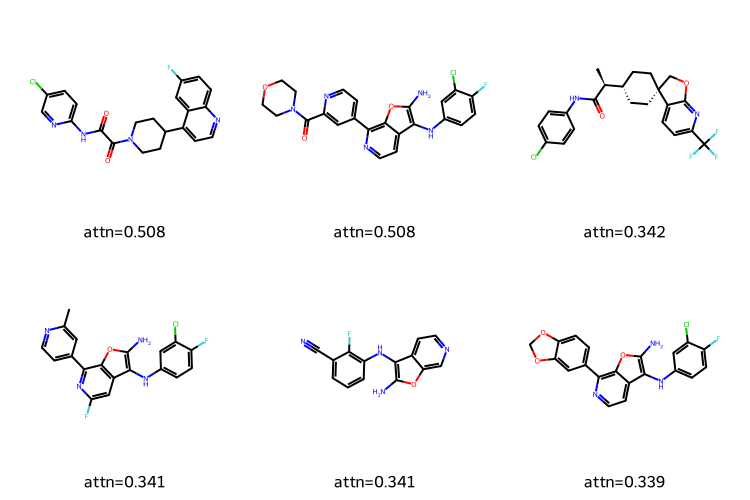

In [93]:
def draw_top_neighbors(cls_name, n=6):
    sub = (attn_df[attn_df["class"] == cls_name]
           .sort_values("attention_weight", ascending=False)
           .drop_duplicates(subset="neighbor_smiles")
           .head(n))
    mols, legends = [], []
    for _, row in sub.iterrows():
        mol = Chem.MolFromSmiles(row["neighbor_smiles"])
        if mol is not None:
            mols.append(mol)
            legends.append(f"attn={row['attention_weight']:.3f}")
    if not mols:
        print(f"No valid neighbor molecules found for class {cls_name} "
              f"(check that enough test molecules of this class were correctly "
              f"classified, and that TOP_K / test set size are large enough).")
        return None
    return Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(250, 250), legends=legends)


def save_grid_image(img, path):
    """
    Draw.MolsToGridImage returns a PIL Image in most RDKit setups, but an
    IPython.display.Image (which has .data bytes, not .save()) when RDKit
    detects a notebook/IPythonConsole environment. Handle both.
    """
    if img is None:
        return
    if hasattr(img, "save"):          # PIL.Image
        img.save(path)
    elif hasattr(img, "data"):         # IPython.display.Image
        with open(path, "wb") as f:
            f.write(img.data)
    else:
        raise TypeError(f"Unrecognized image type from MolsToGridImage: {type(img)}")

img_ai = draw_top_neighbors("AI")
save_grid_image(img_ai, "top_attention_neighbors_AI.png")
img_ai

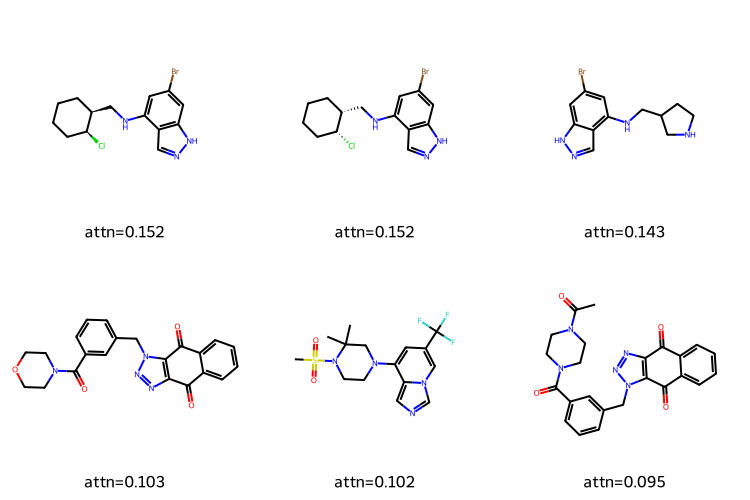

In [94]:
img_ia = draw_top_neighbors("IA")
save_grid_image(img_ia, "top_attention_neighbors_IA.png")
img_ia

In [95]:
def draw_top_scaffold(cls_name):
    top_scaffold_smiles = scaffold_results[cls_name][0][0]
    scaffold_mol = Chem.MolFromSmiles(top_scaffold_smiles)
    drawer = rdMolDraw2D.MolDraw2DCairo(400, 400)
    drawer.DrawMolecule(scaffold_mol)
    drawer.FinishDrawing()
    with open(f"top_scaffold_{cls_name}.png", "wb") as f:
        f.write(drawer.GetDrawingText())
    return scaffold_mol

for cls_name in TARGET_CLASSES:
    if scaffold_results[cls_name]:
        mol = draw_top_scaffold(cls_name)
        print(f"{cls_name} most common scaffold saved: top_scaffold_{cls_name}.png "
              f"(seen {scaffold_results[cls_name][0][1]}x)")

AI most common scaffold saved: top_scaffold_AI.png (seen 10x)
IA most common scaffold saved: top_scaffold_IA.png (seen 3x)


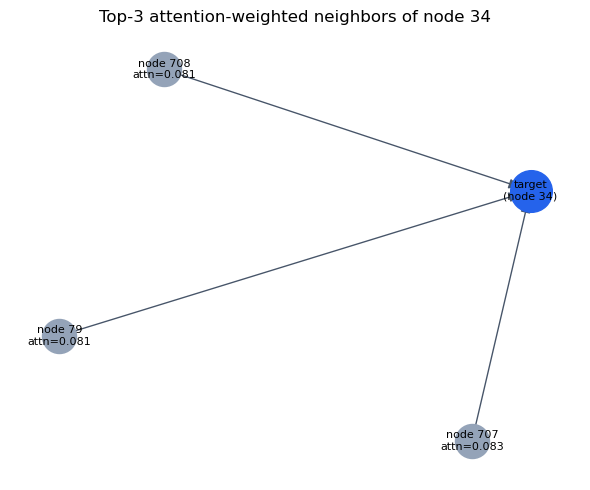

In [96]:
def plot_attention_subgraph(node_idx, k=TOP_K, ax=None):
    neighbors = top_k_neighbors(node_idx, k=k)
    if not neighbors:
        print("No incoming attention edges for this node.")
        return

    G = nx.DiGraph()
    G.add_node(node_idx, label="target")
    for neigh_idx, w in neighbors:
        G.add_node(neigh_idx, label="neighbor")
        G.add_edge(neigh_idx, node_idx, weight=w)

    pos = nx.spring_layout(G, seed=0)
    ax = ax or plt.gca()
    weights = [G[u][v]["weight"] * 12 for u, v in G.edges()]
    nx.draw_networkx_nodes(G, pos, nodelist=[node_idx], node_color="#2563eb",
                             node_size=900, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=[n for n, _ in neighbors], node_color="#94a3b8",
                             node_size=600, ax=ax)
    nx.draw_networkx_edges(G, pos, width=weights, edge_color="#475569",
                             arrows=True, arrowsize=15, ax=ax)
    labels = {node_idx: f"target\n(node {node_idx})"}
    labels.update({n: f"node {n}\nattn={w:.3f}" for n, w in neighbors})
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=8, ax=ax)
    ax.set_title(f"Top-{k} attention-weighted neighbors of node {node_idx}")
    ax.axis("off")

# example: first correctly-classified AI test molecule
example_node = attn_df.loc[attn_df["class"] == "AI", "target_node"].iloc[0]
fig, ax = plt.subplots(figsize=(6, 5))
plot_attention_subgraph(example_node, ax=ax)
plt.tight_layout()
plt.savefig("example_attention_subgraph.png", dpi=200, bbox_inches="tight")
plt.show()

In [97]:
attn_df.to_csv("gat_attention_neighbors_AI_IA.csv", index=False)

scaffold_summary_rows = []
for cls_name, results in scaffold_results.items():
    for rank, (scaf, count) in enumerate(results, start=1):
        scaffold_summary_rows.append({"class": cls_name, "rank": rank,
                                        "scaffold_smiles": scaf, "count": count})
pd.DataFrame(scaffold_summary_rows).to_csv("gat_attention_scaffold_summary.csv", index=False)

print("Saved: gat_attention_neighbors_AI_IA.csv, gat_attention_scaffold_summary.csv")

Saved: gat_attention_neighbors_AI_IA.csv, gat_attention_scaffold_summary.csv
